# S&P 500 next-session direction prediction

At the close of trading session $t$, predict whether each stock's split-adjusted close is higher on the next market session. This notebook uses a shared classifier across tickers and evaluates whether sector-relative features improve out-of-time predictions.

## 1. Define the prediction task

One example is a `(symbol, date)` pair. The target is 1 when the next consecutive market session's close is higher and 0 otherwise. `target_date` and `next_return` are retained for validation and analysis but never used as model inputs.

In [1]:
from pathlib import Path
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

# Change only DATA_DIR when the CSVs live elsewhere.
DATA_DIR = Path("data")
PRICES_FILE = DATA_DIR / "prices-split-adjusted.csv"
SECURITIES_FILE = DATA_DIR / "securities.csv"
DATASET_SOURCE = "Kaggle dgawlik/nyse, version 3; downloaded 2026-11-16"

RETURN_WINDOWS = (1, 5, 20)
ROLLING_WINDOW = 20
TRAIN_END = pd.Timestamp("2014-12-31")
VALIDATION_START = pd.Timestamp("2015-01-01")
VALIDATION_END = pd.Timestamp("2015-12-31")
TEST_START = pd.Timestamp("2016-01-01")
TEST_END = pd.Timestamp("2016-12-31")
RANDOM_SEED = 363
BACKTEST_INITIAL_CAPITAL = 100.0
ROUND_TRIP_COST_BPS = 10.0
TRADING_DAYS_PER_YEAR = 252

pd.set_option("display.max_columns", 100)
print({
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
    "dataset": DATASET_SOURCE,
})

{'python': '3.12.3', 'pandas': '3.1.1', 'numpy': '2.5.5', 'scikit_learn': '1.9.1', 'dataset': 'Kaggle dgawlik/nyse, version 3; downloaded 2026-11-16'}


### Project architecture

The notebook deliberately separates four layers: **data engineering** (raw CSVs to a session-aligned panel), **feature engineering** (past and same-date information only), **model research** (validation-based selection and frozen test evaluation), and **strategy research** (predictions to positions and returns). Assertions at each boundary test schema, time alignment, leakage, and capital accounting.

`raw data → cleaned panel → tested features → frozen model → predictions → explicit strategy → risk and return`

## 2. Load, clean, and explore the data

This section validates the raw schema, reports each cleaning decision, joins sector metadata, and inserts explicit missing rows on absent market sessions. It does not silently treat a ticker's next observed row as its next trading session.

In [2]:
def require_files(*paths):
    missing = [str(path) for path in paths if not path.exists()]
    if missing:
        raise FileNotFoundError(
            "Missing input file(s): " + ", ".join(missing)
            + ". See data/README.md for download instructions."
        )


def find_column(frame, candidates, purpose):
    lookup = {str(column).strip().lower(): column for column in frame.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    raise ValueError(f"Could not find {purpose}; available columns: {list(frame.columns)}")


require_files(PRICES_FILE, SECURITIES_FILE)
prices_raw = pd.read_csv(PRICES_FILE)
securities_raw = pd.read_csv(SECURITIES_FILE)

print("Raw prices shape:", prices_raw.shape)
print("Raw securities shape:", securities_raw.shape)
display(prices_raw.head())
display(securities_raw.head())

Raw prices shape: (851264, 7)
Raw securities shape: (505, 8)


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


,Ticker symbol,Security,SEC filings,GICS Sector,GICS Sub Industry,Address of Headquarters,Date first added,CIK
0,MMM,3M Company,reports,Industrials,Industrial Conglomerates,"St. Paul, Minnesota",NaN,66740
1,ABT,Abbott Laboratories,reports,Health Care,Health Care Equipment,"North Chicago, Illinois",1964-03-31,1800
2,ABBV,AbbVie,reports,Health Care,Pharmaceuticals,"North Chicago, Illinois",2012-12-31,1551152
3,ACN,Accenture plc,reports,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373
4,ATVI,Activision Blizzard,reports,Information Technology,Home Entertainment Software,"Santa Monica, California",2015-08-31,718877


In [3]:
def clean_prices(raw):
    expected = {"date", "symbol", "open", "high", "low", "close", "volume"}
    normalized = {str(column).strip().lower(): column for column in raw.columns}
    missing = expected - set(normalized)
    if missing:
        raise ValueError(f"Prices file is missing columns: {sorted(missing)}")

    frame = raw.rename(columns={normalized[name]: name for name in expected}).copy()
    summary = [{"step": "raw rows", "affected_rows": 0, "remaining_rows": len(frame)}]

    before = len(frame)
    frame = frame.drop_duplicates()
    summary.append({"step": "remove exact duplicates", "affected_rows": before - len(frame), "remaining_rows": len(frame)})

    frame["date"] = pd.to_datetime(frame["date"], errors="coerce")
    frame["symbol"] = frame["symbol"].astype("string").str.strip().str.upper()
    numeric_columns = ["open", "high", "low", "close", "volume"]
    frame[numeric_columns] = frame[numeric_columns].apply(pd.to_numeric, errors="coerce")

    duplicate_key = frame.duplicated(["symbol", "date"], keep=False)
    conflicting_rows = frame.loc[duplicate_key].sort_values(["symbol", "date"])
    if not conflicting_rows.empty:
        display(conflicting_rows.head(20))
        raise ValueError(
            f"Found {duplicate_key.sum():,} conflicting rows sharing (symbol, date). "
            "Inspect the displayed rows and define a documented resolution before continuing."
        )
    summary.append({"step": "conflicting (symbol, date) rows", "affected_rows": int(duplicate_key.sum()), "remaining_rows": len(frame)})

    invalid_key = frame["date"].isna() | frame["symbol"].isna() | frame["symbol"].eq("")
    invalid_close = frame["close"].isna() | frame["close"].le(0)
    invalid_volume = frame["volume"].isna() | frame["volume"].lt(0)
    inconsistent_ohlc = (
        frame[["open", "high", "low"]].isna().any(axis=1)
        | frame["high"].lt(frame[["open", "close", "low"]].max(axis=1))
        | frame["low"].gt(frame[["open", "close", "high"]].min(axis=1))
    )

    for name, mask in [
        ("invalid date or symbol", invalid_key),
        ("missing or nonpositive close", invalid_close),
        ("missing or negative volume", invalid_volume),
        ("missing or inconsistent OHLC range", inconsistent_ohlc),
    ]:
        summary.append({"step": name, "affected_rows": int(mask.sum()), "remaining_rows": None})

    invalid = invalid_key | invalid_close | invalid_volume | inconsistent_ohlc
    frame = frame.loc[~invalid].sort_values(["symbol", "date"]).reset_index(drop=True)
    summary.append({"step": "remove rows failing any validity check", "affected_rows": int(invalid.sum()), "remaining_rows": len(frame)})

    assert not frame.duplicated(["symbol", "date"]).any()
    return frame, pd.DataFrame(summary)


prices, cleaning_summary = clean_prices(prices_raw)
display(cleaning_summary)
print({
    "cleaned_rows": len(prices),
    "date_min": prices["date"].min(),
    "date_max": prices["date"].max(),
    "ticker_count": prices["symbol"].nunique(),
})

,step,affected_rows,remaining_rows
0,raw rows,0,851264.0
1,remove exact duplicates,0,851264.0
2,"conflicting (symbol, date) rows",0,851264.0
3,invalid date or symbol,0,NaN
4,missing or nonpositive close,0,NaN
5,missing or negative volume,0,NaN
6,missing or inconsistent OHLC range,0,NaN
7,remove rows failing any validity check,0,851264.0


{'cleaned_rows': 851264, 'date_min': Timestamp('2010-01-04 00:00:00'), 'date_max': Timestamp('2016-12-30 00:00:00'), 'ticker_count': 501}


In [4]:
ticker_column = find_column(securities_raw, ["Ticker symbol", "symbol", "ticker"], "security ticker column")
sector_column = find_column(securities_raw, ["GICS Sector", "sector"], "GICS sector column")

securities = (
    securities_raw[[ticker_column, sector_column]]
    .rename(columns={ticker_column: "symbol", sector_column: "sector"})
    .assign(
        symbol=lambda x: x["symbol"].astype("string").str.strip().str.upper(),
        sector=lambda x: x["sector"].astype("string").str.strip(),
    )
    .drop_duplicates()
)
if securities["symbol"].duplicated().any():
    display(securities.loc[securities["symbol"].duplicated(keep=False)].sort_values("symbol"))
    raise ValueError("Sector metadata has multiple mappings for at least one ticker.")

prices = prices.merge(securities, on="symbol", how="left", validate="many_to_one")
unmatched = prices["sector"].isna()
print({
    "unmatched_tickers": prices.loc[unmatched, "symbol"].nunique(),
    "unmatched_rows": int(unmatched.sum()),
})

{'unmatched_tickers': 0, 'unmatched_rows': 0}


In [5]:
# The full input panel defines the market-session calendar. Reindex each ticker
# so a missing observation remains explicit and cannot become a one-session return.
sessions = pd.Index(np.sort(prices["date"].unique()), name="date")
symbols = pd.Index(np.sort(prices["symbol"].unique()), name="symbol")
full_index = pd.MultiIndex.from_product([symbols, sessions], names=["symbol", "date"])

panel = (
    prices.set_index(["symbol", "date"])
    .reindex(full_index)
    .reset_index()
)
panel["sector"] = panel.groupby("symbol", sort=False)["sector"].transform(lambda x: x.ffill().bfill())
panel["session_number"] = panel["date"].map(pd.Series(np.arange(len(sessions)), index=sessions))

assert not panel.duplicated(["symbol", "date"]).any()
print({
    "market_sessions": len(sessions),
    "panel_rows": len(panel),
    "observed_price_rows": int(panel["close"].notna().sum()),
    "explicit_missing_rows": int(panel["close"].isna().sum()),
})

{'market_sessions': 1762, 'panel_rows': 882762, 'observed_price_rows': 851264, 'explicit_missing_rows': 31498}


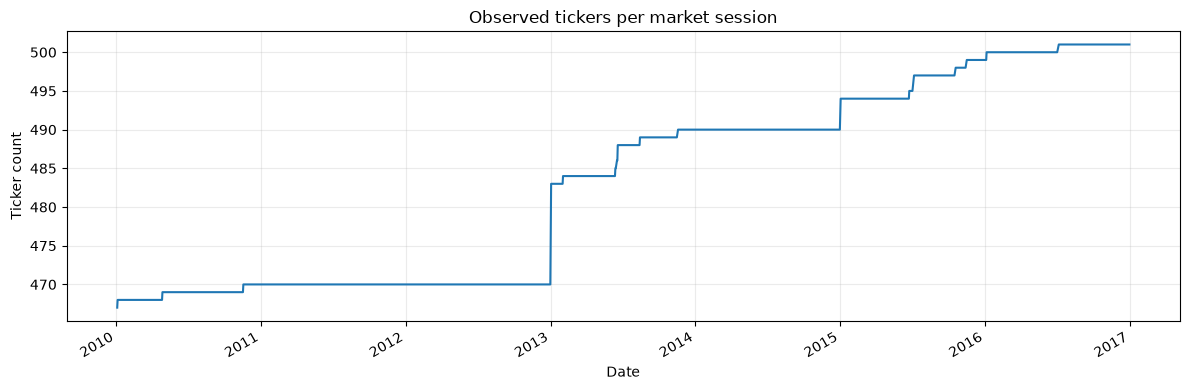

,missing_fraction
open,0.04772
high,0.04772
low,0.04772
close,0.04772
volume,0.04772
sector,0.00000


In [6]:
coverage = panel.groupby("date")["close"].count()
fig, ax = plt.subplots(figsize=(12, 4))
coverage.plot(ax=ax)
ax.set(title="Observed tickers per market session", xlabel="Date", ylabel="Ticker count")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

training_panel = panel.loc[panel["date"].le(TRAIN_END)]
training_missingness = (
    training_panel[["open", "high", "low", "close", "volume", "sector"]]
    .isna().mean().rename("missing_fraction").to_frame()
)
display(training_missingness)

### Cleaning observation

All 851,264 raw price rows passed the key, price, volume, and OHLC validity checks, and all 501 tickers matched sector metadata. The important data issue is incomplete panel coverage: aligning 501 tickers to 1,762 market sessions exposes 31,498 missing stock-session observations. These rows remain missing, preventing a ticker's next observed price after a gap from being mislabeled as the next-session price.

## 3. Engineer and test the features

**Question:** Can trailing stock history predict the next session's direction, and do same-date sector-relative returns add useful information? Features use only the completed session $t$ and earlier observations. Labels are valid only when both $t$ and $t+1$ have prices on consecutive market sessions.

In [7]:
STOCK_FEATURES = [
    "return_1",
    "return_5",
    "return_20",
    "volatility_20",
    "distance_from_ma_20",
    "daily_price_range",
    "relative_volume_20",
]
SECTOR_FEATURES = ["sector_relative_return_1", "sector_relative_return_5"]
STOCK_PLUS_SECTOR_FEATURES = STOCK_FEATURES + SECTOR_FEATURES
IDENTIFIER_AND_TARGET_COLUMNS = [
    "date", "symbol", "sector", "target_date", "next_return", "label"
]

In [8]:
def build_feature_panel(base_panel):
    out = base_panel.sort_values(["symbol", "date"]).reset_index(drop=True).copy()
    grouped = out.groupby("symbol", sort=False)

    # Because every ticker is aligned to the full session index, shift(k) means
    # exactly k market sessions. Require every close in each return window.
    for window in RETURN_WINDOWS:
        previous_close = grouped["close"].shift(window)
        observed_in_window = grouped["close"].transform(
            lambda values, w=window: values.rolling(w + 1, min_periods=w + 1).count()
        )
        out[f"return_{window}"] = (out["close"] / previous_close - 1).where(
            observed_in_window.eq(window + 1)
        )

    out["volatility_20"] = out.groupby("symbol", sort=False)["return_1"].transform(
        lambda values: values.rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).std()
    )
    moving_average = grouped["close"].transform(
        lambda values: values.rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).mean()
    )
    out["distance_from_ma_20"] = out["close"] / moving_average - 1
    out["daily_price_range"] = (out["high"] - out["low"]) / out["close"]

    prior_volume_mean = grouped["volume"].transform(
        lambda values: values.shift(1).rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).mean()
    ).replace(0, np.nan)
    out["relative_volume_20"] = out["volume"] / prior_volume_mean

    # Leave-one-stock-out sector means use only same-date feature values. These
    # aggregates are calculated before filtering on future label availability.
    for window in (1, 5):
        feature = f"return_{window}"
        sector_groups = out.groupby(["date", "sector"], sort=False)[feature]
        sector_sum = sector_groups.transform("sum")
        sector_count = sector_groups.transform("count")
        own_is_valid = out[feature].notna()
        peer_count = sector_count - own_is_valid.astype(int)
        peer_mean = (sector_sum - out[feature]) / peer_count.replace(0, np.nan)
        out[f"sector_relative_return_{window}"] = (
            out[feature] - peer_mean
        ).where(own_is_valid & peer_count.ge(5))

    next_close = grouped["close"].shift(-1)
    out["target_date"] = grouped["date"].shift(-1)
    next_session_number = grouped["session_number"].shift(-1)
    valid_label = (
        out["close"].notna()
        & next_close.notna()
        & next_session_number.sub(out["session_number"]).eq(1)
    )
    out["next_return"] = (next_close / out["close"] - 1).where(valid_label)
    out["label"] = next_close.gt(out["close"]).where(valid_label).astype("Int8")

    return out


feature_panel = build_feature_panel(panel)
MODELING_COLUMNS = IDENTIFIER_AND_TARGET_COLUMNS + STOCK_PLUS_SECTOR_FEATURES
modeling_table = feature_panel.loc[feature_panel["label"].notna(), MODELING_COLUMNS].copy()
display(modeling_table.head())

,date,symbol,sector,target_date,next_return,label,return_1,return_5,return_20,volatility_20,distance_from_ma_20,daily_price_range,relative_volume_20,sector_relative_return_1,sector_relative_return_5
0,2010-01-04,A,Health Care,2010-01-05,-0.010863,0,NaN,NaN,NaN,NaN,NaN,0.015974,NaN,NaN,NaN
1,2010-01-05,A,Health Care,2010-01-06,-0.003553,0,-0.010863,NaN,NaN,NaN,NaN,0.014858,NaN,-0.007259,NaN
2,2010-01-06,A,Health Care,2010-01-07,-0.001297,0,-0.003553,NaN,NaN,NaN,NaN,0.007780,NaN,-0.006184,NaN
3,2010-01-07,A,Health Care,2010-01-08,-0.000325,0,-0.001297,NaN,NaN,NaN,NaN,0.010386,NaN,-0.007661,NaN
4,2010-01-08,A,Health Care,2010-01-11,0.000649,1,-0.000325,NaN,NaN,NaN,NaN,0.014610,NaN,-0.000962,NaN


In [9]:
stock_complete = modeling_table[STOCK_FEATURES].notna().all(axis=1)
sector_complete = modeling_table[STOCK_PLUS_SECTOR_FEATURES].notna().all(axis=1)
feature_coverage = pd.DataFrame([
    {"feature_set": "stock only", "valid_rows": int(stock_complete.sum())},
    {"feature_set": "stock plus sector", "valid_rows": int(sector_complete.sum())},
]).assign(
    coverage_of_labeled_rows=lambda x: x["valid_rows"] / len(modeling_table),
)
shared_modeling_table = modeling_table.loc[sector_complete].copy()
display(feature_coverage)
print("Rows used for fair feature-set comparisons:", f"{len(shared_modeling_table):,}")

,feature_set,valid_rows,coverage_of_labeled_rows
0,stock only,840743,0.988222
1,stock plus sector,832038,0.977990


Rows used for fair feature-set comparisons: 832,038


### Manual and structural checks

The next cells independently recompute one Apple label and five-session return, show a missing-session case, enforce feature-matrix boundaries, and test that changing strictly future data cannot alter current features.

In [10]:
sample_symbol = "AAPL"
sample_date = pd.Timestamp("2014-06-30")
sample_history = feature_panel.loc[feature_panel["symbol"].eq(sample_symbol)].set_index("date")
sample_position = sample_history.index.get_loc(sample_date)
sample_row = sample_history.loc[sample_date]

expected_return_5 = (
    sample_history.iloc[sample_position]["close"]
    / sample_history.iloc[sample_position - 5]["close"]
    - 1
)
expected_next_return = (
    sample_history.iloc[sample_position + 1]["close"]
    / sample_history.iloc[sample_position]["close"]
    - 1
)
assert np.isclose(sample_row["return_5"], expected_return_5)
assert np.isclose(sample_row["next_return"], expected_next_return)
assert sample_row["label"] == int(expected_next_return > 0)
display(
    sample_history.iloc[sample_position - 5:sample_position + 2][
        ["close", "return_5", "target_date", "next_return", "label"]
    ]
)

# The raw data has no observed-then-missing interior gap, so create one in a
# controlled copy and verify that the preceding label becomes unavailable.
synthetic_gap_panel = panel.copy()
gap_date = sample_history.index[sample_position + 1]
gap_row = synthetic_gap_panel["symbol"].eq(sample_symbol) & synthetic_gap_panel["date"].eq(gap_date)
synthetic_gap_panel.loc[gap_row, ["open", "high", "low", "close", "volume"]] = np.nan
synthetic_gap_features = build_feature_panel(synthetic_gap_panel)
before_gap = synthetic_gap_features.loc[
    synthetic_gap_features["symbol"].eq(sample_symbol)
    & synthetic_gap_features["date"].eq(sample_date),
    ["symbol", "date", "close", "target_date", "next_return", "label"],
]
assert before_gap["label"].isna().all()
display(before_gap)
del synthetic_gap_panel, synthetic_gap_features

,close,return_5,target_date,next_return,label
date,,,,,
2014-06-23,90.830002,-0.014859,2014-06-24,-0.006055,0
2014-06-24,90.279999,-0.019548,2014-06-25,0.000886,1
2014-06-25,90.360001,-0.019744,2014-06-26,0.005976,1
2014-06-26,90.900002,-0.010451,2014-06-27,0.011881,1
2014-06-27,91.980003,0.011770,2014-06-30,0.010328,1
2014-06-30,92.930000,0.023120,2014-07-01,0.006349,1
2014-07-01,93.519997,0.035888,2014-07-02,-0.000428,0


,symbol,date,close,target_date,next_return,label
6415,AAPL,2014-06-30,92.93,2014-07-01,NaN,<NA>


### Deterministic feature-engineering tests

A small panel with known prices tests the feature builder independently of the Kaggle data. These are engineering checks: they verify exact formulas and failure behavior, rather than merely checking that the full dataset runs.

In [11]:
def make_synthetic_panel():
    synthetic_dates = pd.date_range("2020-01-02", periods=25, freq="B")
    synthetic_symbols = [f"T{i}" for i in range(7)]
    index = pd.MultiIndex.from_product(
        [synthetic_symbols, synthetic_dates], names=["symbol", "date"]
    )
    frame = index.to_frame(index=False)
    frame["symbol_number"] = frame["symbol"].str[1:].astype(int)
    frame["session_number"] = frame["date"].map(
        pd.Series(np.arange(len(synthetic_dates)), index=synthetic_dates)
    )
    frame["close"] = (
        100
        + 2 * frame["symbol_number"]
        + frame["session_number"] * (1 + 0.1 * frame["symbol_number"])
    ).astype(float)
    frame["open"] = frame["close"] - 0.25
    frame["high"] = frame["close"] + 0.50
    frame["low"] = frame["close"] - 0.50
    frame["volume"] = (
        1_000 + 100 * frame["symbol_number"] + 10 * frame["session_number"]
    ).astype(float)
    frame["sector"] = "Synthetic Sector"
    return frame.drop(columns="symbol_number")


synthetic_panel = make_synthetic_panel()
synthetic_features = build_feature_panel(synthetic_panel)
synthetic_dates = np.sort(synthetic_panel["date"].unique())
check_date = pd.Timestamp(synthetic_dates[20])
check_row = synthetic_features.loc[
    synthetic_features["symbol"].eq("T0") & synthetic_features["date"].eq(check_date)
].iloc[0]
t0 = synthetic_panel.loc[synthetic_panel["symbol"].eq("T0")].set_index("date")

expected_return_5 = t0.loc[check_date, "close"] / t0.iloc[15]["close"] - 1
expected_prior_volume = t0.iloc[:20]["volume"].mean()
expected_volatility = t0["close"].pct_change(fill_method=None).iloc[1:21].std()
peer_returns = (
    synthetic_features.loc[
        synthetic_features["date"].eq(check_date)
        & synthetic_features["symbol"].ne("T0"),
        "return_1",
    ]
)
expected_sector_relative = check_row["return_1"] - peer_returns.mean()

assert np.isclose(check_row["return_5"], expected_return_5)
assert np.isclose(check_row["relative_volume_20"], t0.loc[check_date, "volume"] / expected_prior_volume)
assert np.isclose(check_row["volatility_20"], expected_volatility)
assert np.isclose(check_row["sector_relative_return_1"], expected_sector_relative)

# Removing the next session must invalidate the preceding label.
gap_panel = synthetic_panel.copy()
gap_date = pd.Timestamp(synthetic_dates[21])
gap_mask = gap_panel["symbol"].eq("T0") & gap_panel["date"].eq(gap_date)
gap_panel.loc[gap_mask, ["open", "high", "low", "close", "volume"]] = np.nan
gap_features = build_feature_panel(gap_panel)
label_before_gap = gap_features.loc[
    gap_features["symbol"].eq("T0") & gap_features["date"].eq(check_date), "label"
]
assert label_before_gap.isna().all()

# With only four valid peers, the leave-one-out sector feature must be missing.
few_peer_panel = synthetic_panel.copy()
few_peer_mask = few_peer_panel["symbol"].isin(["T5", "T6"]) & few_peer_panel["date"].eq(check_date)
few_peer_panel.loc[few_peer_mask, ["open", "high", "low", "close", "volume"]] = np.nan
few_peer_features = build_feature_panel(few_peer_panel)
few_peer_value = few_peer_features.loc[
    few_peer_features["symbol"].eq("T0") & few_peer_features["date"].eq(check_date),
    "sector_relative_return_1",
].iloc[0]
assert pd.isna(few_peer_value)

synthetic_test_results = pd.DataFrame({
    "check": [
        "five-session return",
        "prior-volume denominator",
        "20-return volatility",
        "leave-one-out sector return",
        "missing-session label",
        "minimum peer count",
    ],
    "status": "passed",
})
display(synthetic_test_results)
del synthetic_panel, synthetic_features, gap_panel, gap_features, few_peer_panel, few_peer_features

,check,status
0,five-session return,passed
1,prior-volume denominator,passed
2,20-return volatility,passed
3,leave-one-out sector return,passed
4,missing-session label,passed
5,minimum peer count,passed


In [12]:
assert not feature_panel.duplicated(["symbol", "date"]).any()
valid_targets = feature_panel["label"].notna()
target_session = feature_panel["target_date"].map(pd.Series(np.arange(len(sessions)), index=sessions))
assert target_session.loc[valid_targets].sub(
    feature_panel.loc[valid_targets, "session_number"]
).eq(1).all()

X_check = shared_modeling_table[STOCK_PLUS_SECTOR_FEATURES]
assert not set(IDENTIFIER_AND_TARGET_COLUMNS).intersection(X_check.columns)
assert np.isfinite(X_check.to_numpy(dtype=float)).all()
print("Structural checks passed: unique keys, consecutive targets, finite inputs, and no identifiers/targets in X.")

Structural checks passed: unique keys, consecutive targets, finite inputs, and no identifiers/targets in X.


In [13]:
mutation_date = pd.Timestamp("2014-06-30")
mutated_panel = panel.copy()
future_rows = mutated_panel["date"].gt(mutation_date)
mutated_panel.loc[future_rows, ["open", "high", "low", "close"]] *= 1.10
mutated_panel.loc[future_rows, "volume"] *= 2
mutated_features = build_feature_panel(mutated_panel)

original_at_date = (
    feature_panel.loc[feature_panel["date"].eq(mutation_date), ["symbol"] + STOCK_PLUS_SECTOR_FEATURES]
    .sort_values("symbol").reset_index(drop=True)
)
mutated_at_date = (
    mutated_features.loc[mutated_features["date"].eq(mutation_date), ["symbol"] + STOCK_PLUS_SECTOR_FEATURES]
    .sort_values("symbol").reset_index(drop=True)
)
pd.testing.assert_frame_equal(original_at_date, mutated_at_date, check_exact=False, rtol=1e-12, atol=1e-12)

original_labels = feature_panel.loc[feature_panel["date"].eq(mutation_date), "label"].reset_index(drop=True)
mutated_labels = mutated_features.loc[mutated_features["date"].eq(mutation_date), "label"].reset_index(drop=True)
changed_labels = int(original_labels.ne(mutated_labels).fillna(False).sum())
print(f"Leakage test passed: all features on {mutation_date.date()} were unchanged; {changed_labels} future-dependent labels changed.")
del mutated_panel, mutated_features

Leakage test passed: all features on 2014-06-30 were unchanged; 118 future-dependent labels changed.


### Feature observation

The stock-only features are complete for 840,743 labeled rows. Requiring both leave-one-out sector features reduces that to 832,038 rows, a cost of 8,705 observations. Both feature sets will use those same 832,038 rows in the model comparison, ensuring any score change comes from the added sector information rather than a different evaluation sample. The future-mutation test changed 118 next-session labels while leaving every same-date feature unchanged.

## 4. Split and train

All rows on a prediction date stay in the same split. Rows whose next-session target crosses a year boundary are removed from that split. Hyperparameters and the primary model are selected only from 2015 validation ROC-AUC; 2016 remains untouched until final evaluation.

In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [15]:
def rows_within_period(table, start, end):
    return table.loc[
        table["date"].between(start, end, inclusive="both")
        & table["target_date"].between(start, end, inclusive="both")
    ].copy()


TRAIN_START = shared_modeling_table["date"].min()
train_data = rows_within_period(shared_modeling_table, TRAIN_START, TRAIN_END)
validation_data = rows_within_period(shared_modeling_table, VALIDATION_START, VALIDATION_END)
test_data = rows_within_period(shared_modeling_table, TEST_START, TEST_END)

assert train_data["target_date"].max() < validation_data["date"].min()
assert validation_data["target_date"].max() < test_data["date"].min()
assert set(train_data.index).isdisjoint(validation_data.index)
assert set(train_data.index).isdisjoint(test_data.index)
assert set(validation_data.index).isdisjoint(test_data.index)

split_tables = {"train": train_data, "validation": validation_data, "test": test_data}
split_summary = pd.DataFrame([
    {
        "split": name,
        "rows": len(frame),
        "tickers": frame["symbol"].nunique(),
        "prediction_date_min": frame["date"].min(),
        "prediction_date_max": frame["date"].max(),
        "target_date_max": frame["target_date"].max(),
    }
    for name, frame in split_tables.items()
])
display(split_summary)

,split,rows,tickers,prediction_date_min,prediction_date_max,target_date_max
0,train,583707,485,2010-02-02,2014-12-30,2014-12-31
1,validation,123023,494,2015-01-02,2015-12-30,2015-12-31
2,test,124329,496,2016-01-04,2016-12-29,2016-12-30


In [16]:
CLASSIFICATION_THRESHOLD = 0.5
fitted_validation_models = {}
validation_records = []


def validation_metrics(y_true, probabilities, threshold=CLASSIFICATION_THRESHOLD):
    predictions = (probabilities >= threshold).astype("int8")
    return {
        "validation_roc_auc": roc_auc_score(y_true, probabilities),
        "validation_balanced_accuracy": balanced_accuracy_score(y_true, predictions),
        "validation_accuracy": accuracy_score(y_true, predictions),
    }


def fit_validation_model(model_id, model_family, feature_set, features, parameters, model):
    X_train = train_data[features]
    y_train = train_data["label"].astype("int8").to_numpy()
    X_validation = validation_data[features]
    y_validation = validation_data["label"].astype("int8").to_numpy()

    model.fit(X_train, y_train)
    probabilities = model.predict_proba(X_validation)[:, 1]
    metrics = validation_metrics(y_validation, probabilities)
    validation_records.append({
        "model_id": model_id,
        "model_family": model_family,
        "feature_set": feature_set,
        "parameters": parameters,
        **metrics,
    })
    fitted_validation_models[model_id] = model
    print(model_id, {name: round(value, 6) for name, value in metrics.items()})

### Baseline

**Question:** How well does always predicting the training set's majority class perform on 2015?

In [17]:
fit_validation_model(
    model_id="baseline_majority",
    model_family="majority baseline",
    feature_set="stock only",
    features=STOCK_FEATURES,
    parameters={"strategy": "most_frequent"},
    model=DummyClassifier(strategy="most_frequent"),
)

baseline_majority {'validation_roc_auc': 0.5, 'validation_balanced_accuracy': 0.5, 'validation_accuracy': 0.499679}


### Stock-history models

**Question:** With stock-only features, which logistic-regression regularization strength and boosted-tree configuration has the best 2015 ROC-AUC?

In [18]:
for C in (0.1, 1.0, 10.0):
    fit_validation_model(
        model_id=f"logistic_stock_C={C:g}",
        model_family="logistic regression",
        feature_set="stock only",
        features=STOCK_FEATURES,
        parameters={"C": C},
        model=Pipeline([
            ("scale", StandardScaler()),
            ("model", LogisticRegression(C=C, max_iter=1000, random_state=RANDOM_SEED)),
        ]),
    )

for max_leaf_nodes in (15, 31):
    for learning_rate in (0.05, 0.1):
        fit_validation_model(
            model_id=f"boosted_stock_leaves={max_leaf_nodes}_lr={learning_rate:g}",
            model_family="boosted trees",
            feature_set="stock only",
            features=STOCK_FEATURES,
            parameters={
                "max_leaf_nodes": max_leaf_nodes,
                "learning_rate": learning_rate,
                "max_iter": 100,
                "early_stopping": False,
            },
            model=HistGradientBoostingClassifier(
                max_leaf_nodes=max_leaf_nodes,
                learning_rate=learning_rate,
                max_iter=100,
                early_stopping=False,
                random_state=RANDOM_SEED,
            ),
        )

logistic_stock_C=0.1 {'validation_roc_auc': 0.512619, 'validation_balanced_accuracy': 0.503947, 'validation_accuracy': 0.503678}


logistic_stock_C=1 {'validation_roc_auc': 0.51261, 'validation_balanced_accuracy': 0.503947, 'validation_accuracy': 0.503678}


logistic_stock_C=10 {'validation_roc_auc': 0.512609, 'validation_balanced_accuracy': 0.503947, 'validation_accuracy': 0.503678}


boosted_stock_leaves=15_lr=0.05 {'validation_roc_auc': 0.526532, 'validation_balanced_accuracy': 0.508297, 'validation_accuracy': 0.508043}


boosted_stock_leaves=15_lr=0.1 {'validation_roc_auc': 0.524139, 'validation_balanced_accuracy': 0.508997, 'validation_accuracy': 0.508759}


boosted_stock_leaves=31_lr=0.05 {'validation_roc_auc': 0.525098, 'validation_balanced_accuracy': 0.508207, 'validation_accuracy': 0.507962}


boosted_stock_leaves=31_lr=0.1 {'validation_roc_auc': 0.522381, 'validation_balanced_accuracy': 0.509197, 'validation_accuracy': 0.50897}


### Sector-feature models

**Question:** On the identical validation rows, do the two sector-relative returns improve each model family?

In [19]:
for C in (0.1, 1.0, 10.0):
    fit_validation_model(
        model_id=f"logistic_sector_C={C:g}",
        model_family="logistic regression",
        feature_set="stock plus sector",
        features=STOCK_PLUS_SECTOR_FEATURES,
        parameters={"C": C},
        model=Pipeline([
            ("scale", StandardScaler()),
            ("model", LogisticRegression(C=C, max_iter=1000, random_state=RANDOM_SEED)),
        ]),
    )

for max_leaf_nodes in (15, 31):
    for learning_rate in (0.05, 0.1):
        fit_validation_model(
            model_id=f"boosted_sector_leaves={max_leaf_nodes}_lr={learning_rate:g}",
            model_family="boosted trees",
            feature_set="stock plus sector",
            features=STOCK_PLUS_SECTOR_FEATURES,
            parameters={
                "max_leaf_nodes": max_leaf_nodes,
                "learning_rate": learning_rate,
                "max_iter": 100,
                "early_stopping": False,
            },
            model=HistGradientBoostingClassifier(
                max_leaf_nodes=max_leaf_nodes,
                learning_rate=learning_rate,
                max_iter=100,
                early_stopping=False,
                random_state=RANDOM_SEED,
            ),
        )

logistic_sector_C=0.1 {'validation_roc_auc': 0.524186, 'validation_balanced_accuracy': 0.507226, 'validation_accuracy': 0.50697}


logistic_sector_C=1 {'validation_roc_auc': 0.524177, 'validation_balanced_accuracy': 0.507235, 'validation_accuracy': 0.506978}


logistic_sector_C=10 {'validation_roc_auc': 0.524177, 'validation_balanced_accuracy': 0.507235, 'validation_accuracy': 0.506978}


boosted_sector_leaves=15_lr=0.05 {'validation_roc_auc': 0.530642, 'validation_balanced_accuracy': 0.507796, 'validation_accuracy': 0.507539}


boosted_sector_leaves=15_lr=0.1 {'validation_roc_auc': 0.52835, 'validation_balanced_accuracy': 0.508775, 'validation_accuracy': 0.508531}


boosted_sector_leaves=31_lr=0.05 {'validation_roc_auc': 0.529131, 'validation_balanced_accuracy': 0.5085, 'validation_accuracy': 0.508255}


boosted_sector_leaves=31_lr=0.1 {'validation_roc_auc': 0.525651, 'validation_balanced_accuracy': 0.508349, 'validation_accuracy': 0.508116}


In [20]:
validation_results = (
    pd.DataFrame(validation_records)
    .sort_values(["model_family", "feature_set", "validation_roc_auc"], ascending=[True, True, False])
    .reset_index(drop=True)
)
display(validation_results)

candidate_results = validation_results.loc[
    validation_results["model_family"].ne("majority baseline")
].copy()
selected_indices = candidate_results.groupby(
    ["model_family", "feature_set"], sort=False
)["validation_roc_auc"].idxmax()
selected_validation_results = candidate_results.loc[selected_indices].copy()
primary_index = selected_validation_results["validation_roc_auc"].idxmax()
selected_validation_results["primary_model"] = selected_validation_results.index == primary_index
selected_validation_results = selected_validation_results.sort_values("validation_roc_auc", ascending=False)
display(selected_validation_results)

,model_id,model_family,feature_set,parameters,validation_roc_auc,validation_balanced_accuracy,validation_accuracy
0,boosted_stock_leaves=15_lr=0.05,boosted trees,stock only,"{'max_leaf_nodes': 15, 'learning_rate': 0.05, ...",0.526532,0.508297,0.508043
1,boosted_stock_leaves=31_lr=0.05,boosted trees,stock only,"{'max_leaf_nodes': 31, 'learning_rate': 0.05, ...",0.525098,0.508207,0.507962
2,boosted_stock_leaves=15_lr=0.1,boosted trees,stock only,"{'max_leaf_nodes': 15, 'learning_rate': 0.1, '...",0.524139,0.508997,0.508759
3,boosted_stock_leaves=31_lr=0.1,boosted trees,stock only,"{'max_leaf_nodes': 31, 'learning_rate': 0.1, '...",0.522381,0.509197,0.508970
4,boosted_sector_leaves=15_lr=0.05,boosted trees,stock plus sector,"{'max_leaf_nodes': 15, 'learning_rate': 0.05, ...",0.530642,0.507796,0.507539
5,boosted_sector_leaves=31_lr=0.05,boosted trees,stock plus sector,"{'max_leaf_nodes': 31, 'learning_rate': 0.05, ...",0.529131,0.508500,0.508255
6,boosted_sector_leaves=15_lr=0.1,boosted trees,stock plus sector,"{'max_leaf_nodes': 15, 'learning_rate': 0.1, '...",0.528350,0.508775,0.508531
7,boosted_sector_leaves=31_lr=0.1,boosted trees,stock plus sector,"{'max_leaf_nodes': 31, 'learning_rate': 0.1, '...",0.525651,0.508349,0.508116
8,logistic_stock_C=0.1,logistic regression,stock only,{'C': 0.1},0.512619,0.503947,0.503678
9,logistic_stock_C=1,logistic regression,stock only,{'C': 1.0},0.512610,0.503947,0.503678


,model_id,model_family,feature_set,parameters,validation_roc_auc,validation_balanced_accuracy,validation_accuracy,primary_model
4,boosted_sector_leaves=15_lr=0.05,boosted trees,stock plus sector,"{'max_leaf_nodes': 15, 'learning_rate': 0.05, ...",0.530642,0.507796,0.507539,True
0,boosted_stock_leaves=15_lr=0.05,boosted trees,stock only,"{'max_leaf_nodes': 15, 'learning_rate': 0.05, ...",0.526532,0.508297,0.508043,False
11,logistic_sector_C=0.1,logistic regression,stock plus sector,{'C': 0.1},0.524186,0.507226,0.506970,False
8,logistic_stock_C=0.1,logistic regression,stock only,{'C': 0.1},0.512619,0.503947,0.503678,False


In [21]:
FEATURE_SETS = {
    "stock only": STOCK_FEATURES,
    "stock plus sector": STOCK_PLUS_SECTOR_FEATURES,
}
selected_configurations = {}
for _, row in selected_validation_results.iterrows():
    key = (row["model_family"], row["feature_set"])
    selected_configurations[key] = {
        "model_id": row["model_id"],
        "parameters": row["parameters"],
        "features": FEATURE_SETS[row["feature_set"]],
        "threshold": CLASSIFICATION_THRESHOLD,
        "validation_roc_auc": row["validation_roc_auc"],
    }

primary_row = selected_validation_results.loc[primary_index]
PRIMARY_MODEL = {
    "model_family": primary_row["model_family"],
    "feature_set": primary_row["feature_set"],
    **selected_configurations[(primary_row["model_family"], primary_row["feature_set"])],
}

best_feature_comparison = selected_validation_results.pivot(
    index="model_family", columns="feature_set", values="validation_roc_auc"
)
best_feature_comparison["sector_minus_stock_roc_auc"] = (
    best_feature_comparison["stock plus sector"] - best_feature_comparison["stock only"]
)
display(best_feature_comparison)
print("Frozen primary model:", PRIMARY_MODEL)

feature_set,stock only,stock plus sector,sector_minus_stock_roc_auc
model_family,,,
boosted trees,0.526532,0.530642,0.004111
logistic regression,0.512619,0.524186,0.011567


Frozen primary model: {'model_family': 'boosted trees', 'feature_set': 'stock plus sector', 'model_id': 'boosted_sector_leaves=15_lr=0.05', 'parameters': {'max_leaf_nodes': 15, 'learning_rate': 0.05, 'max_iter': 100, 'early_stopping': False}, 'features': ['return_1', 'return_5', 'return_20', 'volatility_20', 'distance_from_ma_20', 'daily_price_range', 'relative_volume_20', 'sector_relative_return_1', 'sector_relative_return_5'], 'threshold': 0.5, 'validation_roc_auc': 0.5306421935023711}


### Validation observation

The selected primary model is a gradient-boosted tree using stock and sector features, 15 maximum leaf nodes, a 0.05 learning rate, and 100 iterations. Its 2015 ROC-AUC is 0.530642, compared with 0.500000 for the majority baseline. Sector features improved the best logistic-regression ROC-AUC from 0.512619 to 0.524186 (+0.011567) and the best boosted-tree ROC-AUC from 0.526532 to 0.530642 (+0.004111). These choices and the 0.5 threshold are now frozen before inspecting 2016 outcomes.

## 5. Evaluate and interpret

The configurations and 0.5 threshold above are fixed. This section refits them on the combined training and validation rows, evaluates each one time on the same held-out 2016 rows, and examines the validation-selected primary model by sector. Test results are descriptive and are not used for further tuning.

In [22]:
# Model selection is frozen, so it is now safe to report label balance for all splits.
label_rate_summary = split_summary[["split", "rows", "tickers"]].copy()
label_rate_summary["positive_label_rate"] = [
    split_tables[name]["label"].mean() for name in label_rate_summary["split"]
]
display(label_rate_summary)

,split,rows,tickers,positive_label_rate
0,train,583707,485,0.519033
1,validation,123023,494,0.499679
2,test,124329,496,0.523691


In [23]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix


def make_frozen_model(model_family, parameters):
    if model_family == "logistic regression":
        return Pipeline([
            ("scale", StandardScaler()),
            ("model", LogisticRegression(
                C=parameters["C"], max_iter=1000, random_state=RANDOM_SEED
            )),
        ])
    if model_family == "boosted trees":
        return HistGradientBoostingClassifier(
            max_leaf_nodes=parameters["max_leaf_nodes"],
            learning_rate=parameters["learning_rate"],
            max_iter=parameters["max_iter"],
            early_stopping=parameters["early_stopping"],
            random_state=RANDOM_SEED,
        )
    if model_family == "majority baseline":
        return DummyClassifier(strategy="most_frequent")
    raise ValueError(f"Unknown model family: {model_family}")


combined_fit_data = (
    pd.concat([train_data, validation_data], axis=0)
    .sort_values(["date", "symbol"])
)
print("Combined 2010–2015 fit rows:", f"{len(combined_fit_data):,}")
print("Untouched 2016 test rows:", f"{len(test_data):,}")

Combined 2010–2015 fit rows: 706,730
Untouched 2016 test rows: 124,329


In [24]:
final_specs = [{
    "model_id": "baseline_majority",
    "model_family": "majority baseline",
    "feature_set": "stock only",
    "features": STOCK_FEATURES,
    "parameters": {"strategy": "most_frequent"},
    "validation_roc_auc": 0.5,
}]
for _, selected in selected_validation_results.iterrows():
    final_specs.append({
        "model_id": selected["model_id"],
        "model_family": selected["model_family"],
        "feature_set": selected["feature_set"],
        "features": FEATURE_SETS[selected["feature_set"]],
        "parameters": selected["parameters"],
        "validation_roc_auc": selected["validation_roc_auc"],
    })

fitted_final_models = {}
test_outputs = {}
final_records = []
y_fit = combined_fit_data["label"].astype("int8").to_numpy()
y_test = test_data["label"].astype("int8").to_numpy()

for spec in final_specs:
    model = make_frozen_model(spec["model_family"], spec["parameters"])
    model.fit(combined_fit_data[spec["features"]], y_fit)
    probabilities = model.predict_proba(test_data[spec["features"]])[:, 1]
    predictions = (probabilities >= CLASSIFICATION_THRESHOLD).astype("int8")

    fitted_final_models[spec["model_id"]] = model
    test_outputs[spec["model_id"]] = pd.DataFrame({
        "probability": probabilities,
        "prediction": predictions,
    }, index=test_data.index)
    final_records.append({
        "model_id": spec["model_id"],
        "model_family": spec["model_family"],
        "feature_set": spec["feature_set"],
        "validation_roc_auc": spec["validation_roc_auc"],
        "test_roc_auc": roc_auc_score(y_test, probabilities),
        "test_balanced_accuracy": balanced_accuracy_score(y_test, predictions),
        "test_accuracy": accuracy_score(y_test, predictions),
    })

result_order = {
    "majority baseline": 0,
    "logistic regression": 1,
    "boosted trees": 2,
}
final_results = pd.DataFrame(final_records)
final_results["display_order"] = final_results["model_family"].map(result_order)
final_results = (
    final_results.sort_values(["display_order", "feature_set"])
    .drop(columns="display_order")
    .reset_index(drop=True)
)
display(final_results)

,model_id,model_family,feature_set,validation_roc_auc,test_roc_auc,test_balanced_accuracy,test_accuracy
0,baseline_majority,majority baseline,stock only,0.500000,0.500000,0.500000,0.523691
1,logistic_stock_C=0.1,logistic regression,stock only,0.512619,0.509219,0.503803,0.520562
2,logistic_sector_C=0.1,logistic regression,stock plus sector,0.524186,0.511411,0.502969,0.516830
3,boosted_stock_leaves=15_lr=0.05,boosted trees,stock only,0.526532,0.523533,0.513486,0.527005
4,boosted_sector_leaves=15_lr=0.05,boosted trees,stock plus sector,0.530642,0.523921,0.512234,0.526024


### Held-out sector-feature comparison

**Question:** Did the validation gains from sector-relative features carry into 2016 for both model families?

In [25]:
family_results = final_results.loc[
    final_results["model_family"].isin(["logistic regression", "boosted trees"])
]
test_feature_comparison = family_results.pivot(
    index="model_family", columns="feature_set", values="test_roc_auc"
)
test_feature_comparison["sector_minus_stock_roc_auc"] = (
    test_feature_comparison["stock plus sector"] - test_feature_comparison["stock only"]
)
display(test_feature_comparison)

feature_set,stock only,stock plus sector,sector_minus_stock_roc_auc
model_family,,,
boosted trees,0.523533,0.523921,0.000388
logistic regression,0.509219,0.511411,0.002191


### Primary-model confusion matrix

The primary model and threshold were chosen on validation data. This matrix shows its unnormalized held-out classification counts.

,predicted down/flat,predicted up
actual down/flat,13100,46119
actual up,12810,52300


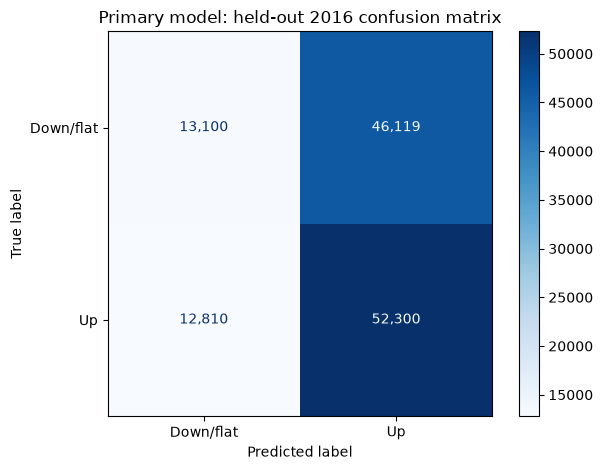

In [26]:
primary_model_id = PRIMARY_MODEL["model_id"]
primary_output = test_outputs[primary_model_id]
primary_confusion = confusion_matrix(y_test, primary_output["prediction"])
display(pd.DataFrame(
    primary_confusion,
    index=["actual down/flat", "actual up"],
    columns=["predicted down/flat", "predicted up"],
))
ConfusionMatrixDisplay(
    confusion_matrix=primary_confusion,
    display_labels=["Down/flat", "Up"],
).plot(cmap="Blues", values_format=",d")
plt.title("Primary model: held-out 2016 confusion matrix")
plt.tight_layout()
plt.show()

### Illustrative $100 even-money simulation

This is a classification-payoff illustration, not a trading backtest. It divides $100 equally across all held-out predictions; each correct prediction earns one stake and each incorrect prediction loses one stake. It ignores actual return sizes, overlapping positions, transaction costs, spreads, and market impact.

In [27]:
INITIAL_CAPITAL = BACKTEST_INITIAL_CAPITAL

primary_predictions = primary_output["prediction"].to_numpy()
correct_predictions = int((primary_predictions == y_test).sum())
incorrect_predictions = int((primary_predictions != y_test).sum())
number_of_bets = len(y_test)
stake_per_prediction = INITIAL_CAPITAL / number_of_bets

gross_winnings = correct_predictions * stake_per_prediction
gross_losses = incorrect_predictions * stake_per_prediction
net_profit = gross_winnings - gross_losses
final_value = INITIAL_CAPITAL + net_profit
return_percent = 100 * net_profit / INITIAL_CAPITAL

even_money_simulation = pd.DataFrame([{
    "initial_capital": INITIAL_CAPITAL,
    "test_predictions": number_of_bets,
    "correct_predictions": correct_predictions,
    "incorrect_predictions": incorrect_predictions,
    "stake_per_prediction": stake_per_prediction,
    "net_profit": net_profit,
    "return_percent": return_percent,
    "final_value": final_value,
}])

assert correct_predictions + incorrect_predictions == number_of_bets
assert np.isclose(
    final_value,
    INITIAL_CAPITAL * (1 + (correct_predictions - incorrect_predictions) / number_of_bets),
)
display(even_money_simulation)
print(f"Final value: ${final_value:,.2f} (profit ${net_profit:,.2f}, return {return_percent:.2f}%)")

,initial_capital,test_predictions,correct_predictions,incorrect_predictions,stake_per_prediction,net_profit,return_percent,final_value
0,100.0,124329,65400,58929,0.000804,5.204739,5.204739,105.204739


Final value: $105.20 (profit $5.20, return 5.20%)


### Primary-model performance by sector

**Question:** Is aggregate performance broad across sectors, or is it supported by only one or two large sectors? Sector labels are treated as the supplied metadata snapshot, not time-varying historical classifications.

,stock_days,tickers,roc_auc,balanced_accuracy,accuracy,support_share
sector,,,,,,
Consumer Staples,9036.0,36.0,0.535538,0.515037,0.528663,0.072678
Health Care,14809.0,59.0,0.535029,0.520537,0.528192,0.119111
Energy,9036.0,36.0,0.533902,0.524581,0.525675,0.072678
Information Technology,17068.0,68.0,0.530479,0.515153,0.532986,0.137281
Financials,15541.0,62.0,0.528115,0.510951,0.527572,0.124999
Utilities,7028.0,28.0,0.523200,0.512510,0.548520,0.056527
Industrials,17173.0,69.0,0.523034,0.506999,0.524952,0.138125
Materials,6275.0,25.0,0.515697,0.512968,0.527809,0.050471
Consumer Discretionary,21084.0,84.0,0.511050,0.506854,0.510909,0.169582


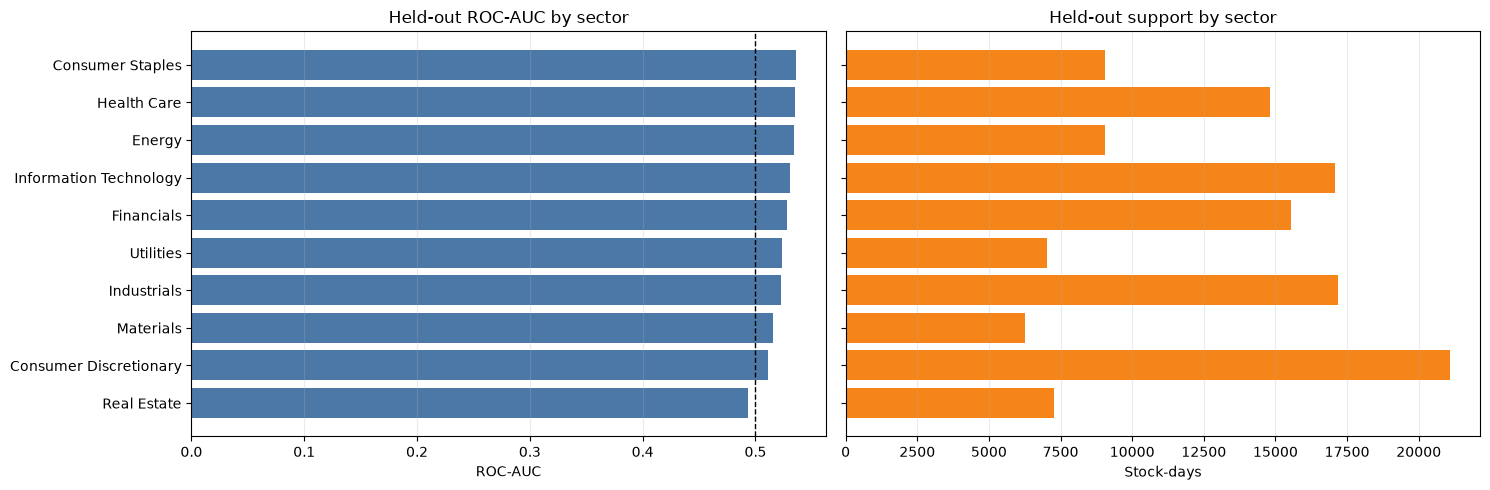

Largest two sectors' share of test rows: 30.8%


In [28]:
sector_test = test_data[["sector", "symbol", "label"]].copy()
sector_test["probability"] = primary_output["probability"]
sector_test["prediction"] = primary_output["prediction"]

def summarize_sector(group):
    truth = group["label"].astype("int8").to_numpy()
    return pd.Series({
        "stock_days": len(group),
        "tickers": group["symbol"].nunique(),
        "roc_auc": roc_auc_score(truth, group["probability"]),
        "balanced_accuracy": balanced_accuracy_score(truth, group["prediction"]),
        "accuracy": accuracy_score(truth, group["prediction"]),
    })

sector_results = (
    sector_test.groupby("sector", observed=True)
    .apply(summarize_sector, include_groups=False)
    .sort_values("roc_auc", ascending=False)
)
sector_results["support_share"] = sector_results["stock_days"] / sector_results["stock_days"].sum()
display(sector_results)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
plot_order = sector_results.sort_values("roc_auc").index
axes[0].barh(plot_order, sector_results.loc[plot_order, "roc_auc"], color="#4C78A8")
axes[0].axvline(0.5, color="black", linestyle="--", linewidth=1)
axes[0].set(title="Held-out ROC-AUC by sector", xlabel="ROC-AUC")
axes[1].barh(plot_order, sector_results.loc[plot_order, "stock_days"], color="#F58518")
axes[1].set(title="Held-out support by sector", xlabel="Stock-days")
for ax in axes:
    ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

largest_two_support = sector_results.nlargest(2, "stock_days")["support_share"].sum()
print("Largest two sectors' share of test rows:", f"{largest_two_support:.1%}")

### Model interpretation

Standardized logistic coefficients describe the direction and relative scale of the linear model's associations. Permutation importance measures the primary model's held-out ROC-AUC decrease when one feature is shuffled. The latter is descriptive test analysis, not an additional selection step.

,feature,standardized_coefficient,absolute_coefficient
1,return_5,-0.114277,0.114277
8,sector_relative_return_5,0.085338,0.085338
2,return_20,-0.040509,0.040509
5,daily_price_range,-0.030523,0.030523
4,distance_from_ma_20,0.017183,0.017183
0,return_1,-0.014263,0.014263
6,relative_volume_20,0.002537,0.002537
7,sector_relative_return_1,0.001322,0.001322
3,volatility_20,0.000712,0.000712


,feature,roc_auc_decrease_mean,roc_auc_decrease_std
1,return_5,0.008618,0.001557
0,return_1,0.008059,0.002741
8,sector_relative_return_5,0.007503,0.001234
2,return_20,0.003877,0.002082
5,daily_price_range,0.002958,0.001576
3,volatility_20,-0.000434,0.001348
6,relative_volume_20,-0.000641,0.002223
4,distance_from_ma_20,-0.001121,0.000572
7,sector_relative_return_1,-0.001679,0.000345


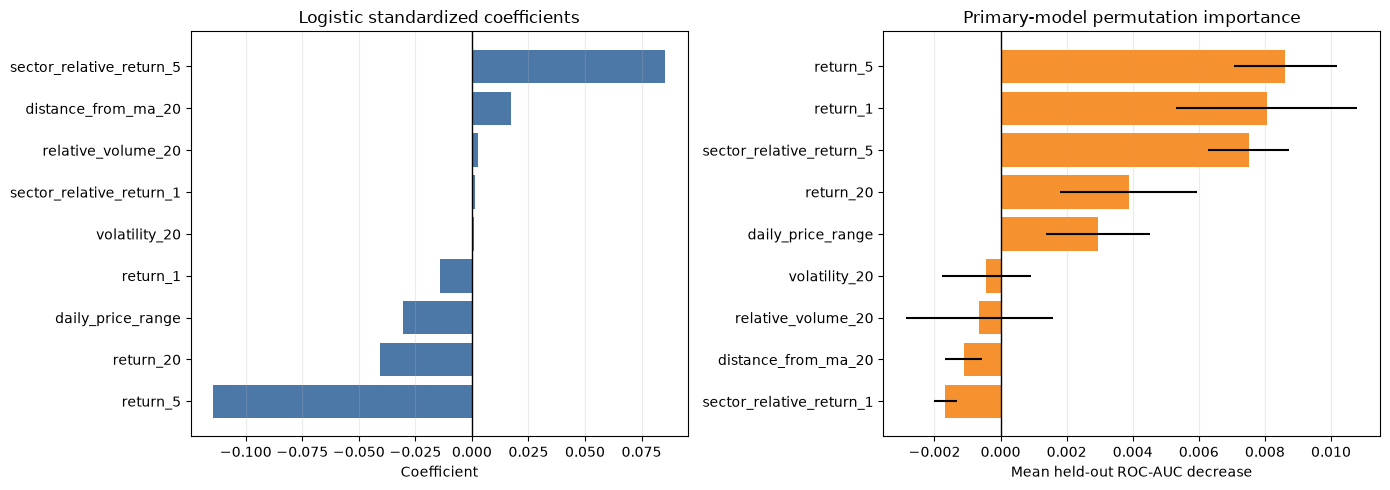

In [29]:
from sklearn.inspection import permutation_importance

logistic_sector_id = selected_validation_results.loc[
    selected_validation_results["model_family"].eq("logistic regression")
    & selected_validation_results["feature_set"].eq("stock plus sector"),
    "model_id",
].iloc[0]
logistic_pipeline = fitted_final_models[logistic_sector_id]
coefficient_table = (
    pd.DataFrame({
        "feature": STOCK_PLUS_SECTOR_FEATURES,
        "standardized_coefficient": logistic_pipeline.named_steps["model"].coef_[0],
    })
    .assign(absolute_coefficient=lambda x: x["standardized_coefficient"].abs())
    .sort_values("absolute_coefficient", ascending=False)
)

importance_sample = test_data.sample(
    n=min(20_000, len(test_data)), random_state=RANDOM_SEED
)
importance_result = permutation_importance(
    fitted_final_models[primary_model_id],
    importance_sample[PRIMARY_MODEL["features"]],
    importance_sample["label"].astype("int8"),
    scoring="roc_auc",
    n_repeats=5,
    random_state=RANDOM_SEED,
    n_jobs=1,
)
permutation_table = (
    pd.DataFrame({
        "feature": PRIMARY_MODEL["features"],
        "roc_auc_decrease_mean": importance_result.importances_mean,
        "roc_auc_decrease_std": importance_result.importances_std,
    })
    .sort_values("roc_auc_decrease_mean", ascending=False)
)
display(coefficient_table)
display(permutation_table)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
coef_plot = coefficient_table.sort_values("standardized_coefficient")
axes[0].barh(coef_plot["feature"], coef_plot["standardized_coefficient"], color="#4C78A8")
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set(title="Logistic standardized coefficients", xlabel="Coefficient")
perm_plot = permutation_table.sort_values("roc_auc_decrease_mean")
axes[1].barh(
    perm_plot["feature"], perm_plot["roc_auc_decrease_mean"],
    xerr=perm_plot["roc_auc_decrease_std"], color="#F58518", alpha=0.9,
)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set(title="Primary-model permutation importance", xlabel="Mean held-out ROC-AUC decrease")
for ax in axes:
    ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### Return-based strategy simulation

The prediction model and trading policy are separate. Three daily, equal-gross-exposure policies are compared on the same 2016 stock-days: (1) an equal-weight always-long benchmark, (2) a long-only policy that allocates across predicted-up stocks and otherwise holds cash, and (3) a long/short policy that buys predicted-up stocks and shorts predicted-down stocks. Capital is rebalanced and compounded daily.

**Execution limitation:** `next_return` is close-to-close, while the features use the completed close at $t$. Entering at that same close is not generally executable after observing it. Therefore this is a research approximation unless signals can be formed before and executed in the closing auction. A deployable next-open strategy would require redefining the target and rebuilding the experiment.

In [30]:
strategy_rows = test_data[["date", "symbol", "next_return"]].copy()
strategy_rows["prediction"] = primary_output["prediction"].astype("int8")
strategy_rows["always_long_raw"] = 1.0
strategy_rows["model_long_only_raw"] = strategy_rows["prediction"].astype(float)
strategy_rows["model_long_short_raw"] = 2.0 * strategy_rows["prediction"] - 1.0

strategy_names = ["always_long", "model_long_only", "model_long_short"]
daily_returns = {}
strategy_weights = {}
cost_rate = ROUND_TRIP_COST_BPS / 10_000

for strategy_name in strategy_names:
    raw_position = strategy_rows[f"{strategy_name}_raw"]
    gross_denominator = raw_position.abs().groupby(strategy_rows["date"]).transform("sum")
    weights = raw_position.div(gross_denominator.replace(0, np.nan)).fillna(0.0)
    gross_exposure = weights.abs().groupby(strategy_rows["date"]).sum()
    gross_daily_return = (weights * strategy_rows["next_return"]).groupby(strategy_rows["date"]).sum()

    # Conservative simplification: all exposure is treated as a one-day round trip.
    # The configured cost therefore applies to gross exposure every session.
    net_daily_return = gross_daily_return - cost_rate * gross_exposure
    strategy_weights[strategy_name] = weights
    daily_returns[(strategy_name, "gross")] = gross_daily_return
    daily_returns[(strategy_name, "net")] = net_daily_return

backtest_daily = pd.DataFrame(daily_returns).sort_index()
backtest_daily.columns = pd.MultiIndex.from_tuples(backtest_daily.columns, names=["strategy", "return_type"])
assert np.isfinite(backtest_daily.to_numpy()).all()
assert (backtest_daily > -1).all().all()
for strategy_name, weights in strategy_weights.items():
    exposure = weights.abs().groupby(strategy_rows["date"]).sum()
    assert np.allclose(exposure.to_numpy(), 1.0)
print(
    f"Strategy accounting checks passed for {len(backtest_daily)} sessions; "
    f"assumed round-trip cost is {ROUND_TRIP_COST_BPS:g} bps per fully invested day."
)

Strategy accounting checks passed for 251 sessions; assumed round-trip cost is 10 bps per fully invested day.


In [31]:
def calculate_backtest_metrics(daily_return, initial_capital=BACKTEST_INITIAL_CAPITAL):
    equity = initial_capital * (1 + daily_return).cumprod()
    drawdown = equity / equity.cummax() - 1
    volatility = daily_return.std()
    return pd.Series({
        "sessions": len(daily_return),
        "final_value": equity.iloc[-1],
        "total_return": equity.iloc[-1] / initial_capital - 1,
        "annualized_volatility": volatility * np.sqrt(TRADING_DAYS_PER_YEAR),
        "annualized_sharpe": (
            daily_return.mean() / volatility * np.sqrt(TRADING_DAYS_PER_YEAR)
            if volatility > 0 else np.nan
        ),
        "maximum_drawdown": drawdown.min(),
        "positive_day_rate": daily_return.gt(0).mean(),
    })


backtest_records = []
equity_curves = {}
for strategy_name in strategy_names:
    for return_type in ("gross", "net"):
        returns = backtest_daily[(strategy_name, return_type)]
        metrics = calculate_backtest_metrics(returns)
        backtest_records.append({
            "strategy": strategy_name,
            "return_type": return_type,
            **metrics.to_dict(),
        })
        equity_curves[(strategy_name, return_type)] = BACKTEST_INITIAL_CAPITAL * (1 + returns).cumprod()

backtest_results = pd.DataFrame(backtest_records)
equity_curves = pd.DataFrame(equity_curves)
equity_curves.columns = pd.MultiIndex.from_tuples(equity_curves.columns, names=["strategy", "return_type"])
for strategy_name in strategy_names:
    expected_final = BACKTEST_INITIAL_CAPITAL * (
        1 + backtest_daily[(strategy_name, "net")]
    ).prod()
    observed_final = backtest_results.loc[
        backtest_results["strategy"].eq(strategy_name)
        & backtest_results["return_type"].eq("net"),
        "final_value",
    ].iloc[0]
    assert np.isclose(expected_final, observed_final)
display(backtest_results)

,strategy,return_type,sessions,final_value,total_return,annualized_volatility,annualized_sharpe,maximum_drawdown,positive_day_rate
0,always_long,gross,251.0,115.664549,0.156645,0.149646,1.051318,-0.106391,0.549801
1,always_long,net,251.0,89.990404,-0.100096,0.149646,-0.632661,-0.138419,0.494024
2,model_long_only,gross,251.0,121.287040,0.212870,0.143784,1.419726,-0.106215,0.553785
3,model_long_only,net,251.0,94.369433,-0.056306,0.143784,-0.332903,-0.129266,0.494024
4,model_long_short,gross,251.0,120.438296,0.204383,0.102341,1.875986,-0.075629,0.569721
5,model_long_short,net,251.0,93.708871,-0.062911,0.102341,-0.586362,-0.099437,0.450199


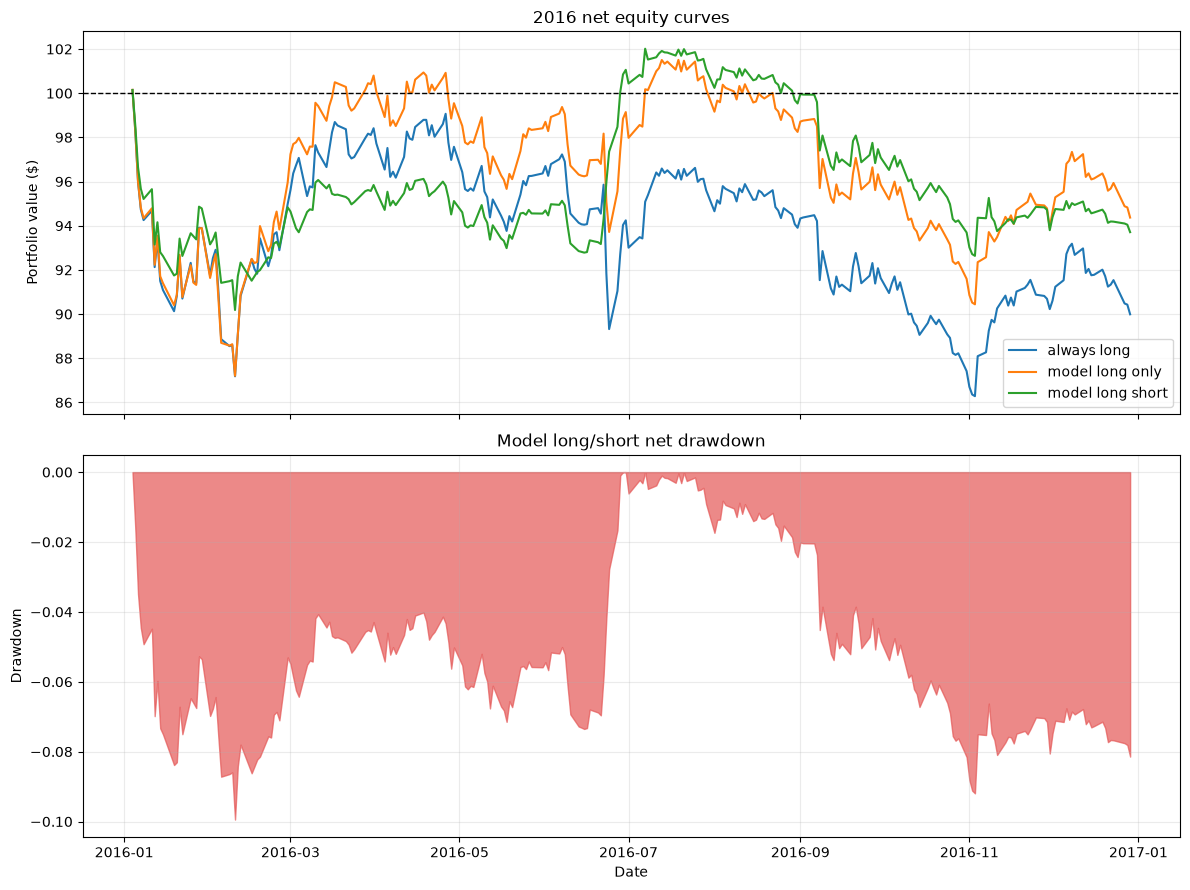

In [32]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
for strategy_name in strategy_names:
    curve = equity_curves[(strategy_name, "net")]
    axes[0].plot(curve.index, curve, label=strategy_name.replace("_", " "))
axes[0].axhline(BACKTEST_INITIAL_CAPITAL, color="black", linestyle="--", linewidth=1)
axes[0].set(title="2016 net equity curves", ylabel="Portfolio value ($)")
axes[0].legend()

primary_curve = equity_curves[("model_long_short", "net")]
primary_drawdown = primary_curve / primary_curve.cummax() - 1
axes[1].fill_between(primary_drawdown.index, primary_drawdown, 0, color="#E45756", alpha=0.7)
axes[1].set(title="Model long/short net drawdown", xlabel="Date", ylabel="Drawdown")
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Strategy observation

Before costs, $100 grew to $115.66 for the daily equal-weight always-long benchmark, $121.29 for the model's long-only policy, and $120.44 for its long/short policy. The long/short version had the strongest gross risk-adjusted profile (annualized Sharpe 1.876 and maximum drawdown -7.56%), while long-only produced the highest ending value. Under the deliberately conservative assumption of a complete 10-basis-point round trip every day, all three strategies lost money: their ending values fell to $89.99, $94.37, and $93.71, respectively. The apparent gross edge is therefore economically sensitive to turnover and costs. These close-to-close results remain a research approximation, not an executable backtest.

## Summary

The validation-selected boosted-tree model with sector features achieved 0.523921 ROC-AUC on the held-out 2016 rows, above the majority baseline's 0.500000 but below its own 0.530642 validation score. Its accuracy was 0.526024 versus 0.523691 for the baseline, a gain of only 0.002333, while balanced accuracy improved from 0.500000 to 0.512234. Sector-relative features helped held-out ROC-AUC in both families, but the gains shrank to +0.002191 for logistic regression and +0.000388 for boosted trees. Thus the direction of the sector effect carried to test, but most of its apparent validation benefit did not.

At the fixed 0.5 threshold, the primary model predicted up on 79.2% of test rows. It identified 80.3% of actual up sessions but only 22.1% of down or flat sessions, so weak discrimination of the latter class is the main classification failure. Sector ROC-AUC ranged from 0.535538 for Consumer Staples to 0.493566 for Real Estate; nine of ten sectors were above 0.5. The two largest sectors supplied 30.8% of test rows, so the aggregate result was not supported by only one or two sectors, although performance was uneven.

The return-based simulation reinforces that distinction. Before costs, the model long-only and long/short policies ended at $121.29 and $120.44, compared with $115.66 for the always-long benchmark. With the configured 10-basis-point full daily round-trip cost, they ended below their starting capital at $94.37 and $93.71. The earlier $105.20 even-money result is only a classification-payoff illustration and is not comparable to this actual-return simulation. Five-session stock return was the strongest feature in both standardized logistic magnitude and held-out permutation importance; the five-session sector-relative return also contributed, consistent with the sector experiment.

These results do not establish a deployable or generally profitable trading strategy. The features require the completed close at $t$ while the simulated return begins at that close, so executable timing would require closing-auction signals formed before the close or a redesigned next-open target. Conclusions are also limited to the supplied tickers and snapshot sector labels; transaction-cost assumptions, changing index membership, survivorship, slippage, and market impact can materially change the result.